In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(1)
print("torch", torch.__version__)

torch 2.15.0+cpu


In [2]:
KAGGLE_DIR = "/kaggle/input/eds-232-ocean-chemistry-prediction-for-calcofi"
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else "."

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print("train", train.shape, " test", test.shape, " sample", sample.shape)
train.head()

train (1454, 19)  test (485, 17)  sample (485, 2)


,id,Lat_Dec,Lon_Dec,NO2uM,NO3uM,NH3uM,R_TEMP,R_Depth,R_Sal,R_DYNHT,R_Nuts,R_Oxy_micromol.Kg,Unnamed: 12,PO4uM,SiO3uM,TA1.x,Salinity1,Temperature_degC,DIC
0,1,34.385030,-120.665530,0.030,33.80,0.00,7.79,323,141.2,0.642,0.00,37.40948,NaN,2.77,53.86,2287.45,34.198,7.82,2270.17
1,2,31.418333,-121.998333,0.000,34.70,0.00,7.12,323,140.8,0.767,0.00,64.81441,NaN,2.57,52.50,2279.10,34.074,7.15,2254.10
2,3,34.385030,-120.665530,0.180,14.20,0.00,11.68,50,246.8,0.144,0.00,180.29150,NaN,1.29,13.01,2230.80,33.537,11.68,2111.04
3,4,33.482580,-122.533070,0.013,29.67,0.01,8.33,232,158.5,0.562,0.01,89.62595,NaN,2.27,38.98,2265.85,34.048,8.36,2223.41
4,5,31.414320,-121.997670,0.000,33.10,0.05,7.53,323,143.4,0.740,0.05,60.03062,NaN,2.53,49.28,2278.49,34.117,7.57,2252.62


In [3]:
FEATURES = [
    "Lat_Dec", "Lon_Dec", "NO2uM", "NO3uM", "NH3uM", "R_TEMP", "R_Depth", "R_Sal",
    "R_DYNHT", "R_Nuts", "R_Oxy_micromol.Kg", "PO4uM", "SiO3uM", "Salinity1", "Temperature_degC",
]
print("train にだけある全欠損列:", [c for c in train.columns if train[c].isna().all()])
common = train.drop(columns=["Unnamed: 12", "id", "DIC"]).columns.intersection(test.columns)
assert list(common) == FEATURES
print("入力列はベースラインと一致:", len(FEATURES), "列")

X = train[FEATURES].values
y = train["DIC"].values
X_test = test[FEATURES].values
print("欠損値 train:", np.isnan(X).sum(), " test:", np.isnan(X_test).sum())

train にだけある全欠損列: ['Unnamed: 12']
入力列はベースラインと一致: 15 列
欠損値 train: 0  test: 0


count    1454.00
mean     2150.47
std       113.16
min      1948.85
25%      2025.82
50%      2166.63
75%      2252.66
max      2367.80
Name: DIC, dtype: float64

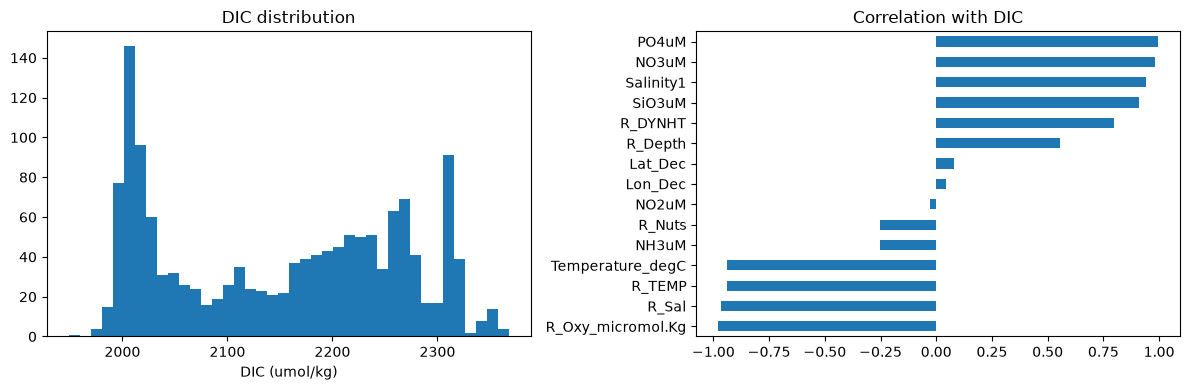

In [4]:
print(train["DIC"].describe().round(2))
corr = train[FEATURES + ["DIC"]].corr()["DIC"].drop("DIC").sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=40)
ax[0].set_title("DIC distribution")
ax[0].set_xlabel("DIC (umol/kg)")
corr.plot.barh(ax=ax[1])
ax[1].set_title("Correlation with DIC")
plt.tight_layout()
plt.show()

In [5]:
print("R_Nuts == NH3uM (全行):", (train["R_Nuts"] == train["NH3uM"]).all())
print("corr(R_TEMP, Temperature_degC):", round(train["R_TEMP"].corr(train["Temperature_degC"]), 5))
print("NO2uM 上位:", train["NO2uM"].nlargest(4).tolist())

R_Nuts == NH3uM (全行): True
corr(R_TEMP, Temperature_degC): 0.99998
NO2uM 上位: [8.19, 6.19, 0.753, 0.72]


In [6]:
class Net(nn.Module):
    def __init__(self, d_in, hidden=128, depth=2, skip=True):
        super().__init__()
        layers, d = [], d_in
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.mlp = nn.Sequential(*layers)
        self.skip = nn.Linear(d_in, 1) if skip else None

    def forward(self, x):
        out = self.mlp(x)
        if self.skip is not None:
            out = out + self.skip(x)
        return out.squeeze(-1)

In [7]:
CFG = dict(hidden=128, depth=2, skip=True, lr=3e-3, wd=1e-4, epochs=300, bs=32, loss="huber", delta=0.05)


def fit_predict(X_tr, y_tr, X_preds, cfg, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    xs = StandardScaler().fit(X_tr)
    y_mu, y_sd = y_tr.mean(), y_tr.std()
    Xt = torch.tensor(xs.transform(X_tr), dtype=torch.float32)
    yt = torch.tensor((y_tr - y_mu) / y_sd, dtype=torch.float32)

    model = Net(Xt.shape[1], cfg["hidden"], cfg["depth"], cfg["skip"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    n, bs = len(Xt), cfg["bs"]
    steps = cfg["epochs"] * int(np.ceil(n / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=steps)
    loss_fn = nn.MSELoss() if cfg["loss"] == "mse" else nn.HuberLoss(delta=cfg["delta"])

    model.train()
    for _ in range(cfg["epochs"]):
        perm = torch.randperm(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss_fn(model(Xt[idx]), yt[idx]).backward()
            opt.step()
            sched.step()

    model.eval()
    with torch.no_grad():
        return [model(torch.tensor(xs.transform(Xp), dtype=torch.float32)).numpy() * y_sd + y_mu for Xp in X_preds]

In [8]:
SPLIT_SEEDS = (42, 2026)
SEEDS = (0, 1, 2)
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))

split_oofs = []
test_pred = np.zeros(len(X_test))
for split_seed in SPLIT_SEEDS:
    folds = list(KFold(5, shuffle=True, random_state=split_seed).split(X))
    oofs = np.zeros((len(SEEDS), len(y)))
    for si, s in enumerate(SEEDS):
        for k, (tr, va) in enumerate(folds):
            p_va, p_te = fit_predict(X[tr], y[tr], [X[va], X_test], CFG, seed=1000 * s + k)
            oofs[si, va] = p_va
            test_pred += p_te / (len(SPLIT_SEEDS) * len(SEEDS) * len(folds))
    split_oofs.append(oofs.mean(0))
    print(f"分割 seed {split_seed}: 単体 {[round(rmse(o, y), 4) for o in oofs]}  "
          f"seed 平均 {rmse(oofs.mean(0), y):.4f}  fold 別 {[round(rmse(oofs.mean(0)[va], y[va]), 3) for _, va in folds]}")

oof = np.mean(split_oofs, axis=0)
print(f"2 分割平均 OOF RMSE = {rmse(oof, y):.4f}")

分割 seed 42: 単体 [5.1529, 5.1334, 5.0565]  seed 平均 5.0816  fold 別 [4.864, 4.313, 5.229, 5.15, 5.745]


分割 seed 2026: 単体 [5.2895, 5.1598, 5.0721]  seed 平均 5.1202  fold 別 [6.18, 4.875, 3.564, 5.817, 4.75]
2 分割平均 OOF RMSE = 5.0746


上位 5 行の二乗誤差の割合: 37.1%
誤差の絶対値の中央値: 1.43


,id,R_Depth,PO4uM,R_Oxy_micromol.Kg,DIC,pred,residual
1086,1087,169,2.05,112.26310,2264.81,2198.1,-66.7
1409,1410,101,2.34,65.26867,2286.75,2231.5,-55.3
33,34,520,3.04,13.91655,2362.15,2307.3,-54.8
461,462,19,0.25,247.30300,2039.71,1998.1,-41.6
249,250,172,2.06,110.52680,2238.80,2197.8,-41.0


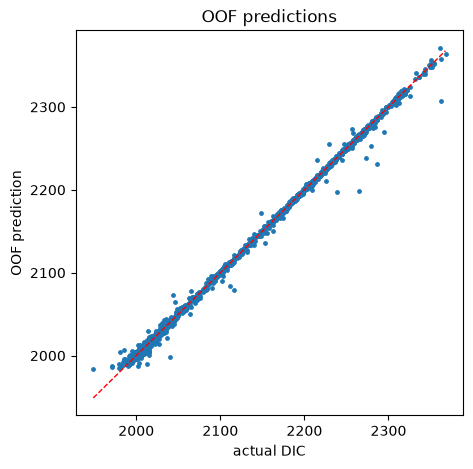

In [9]:
res = oof - y
sq = np.sort(res ** 2)[::-1]
print(f"上位 5 行の二乗誤差の割合: {sq[:5].sum() / sq.sum():.1%}")
print(f"誤差の絶対値の中央値: {np.median(np.abs(res)):.2f}")
top = np.argsort(-np.abs(res))[:5]
display(train.loc[top, ["id", "R_Depth", "PO4uM", "R_Oxy_micromol.Kg", "DIC"]].assign(pred=oof[top].round(1), residual=res[top].round(1)))

plt.figure(figsize=(5, 5))
plt.scatter(y, oof, s=6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=1)
plt.xlabel("actual DIC")
plt.ylabel("OOF prediction")
plt.title("OOF predictions")
plt.show()

In [10]:
submission = pd.DataFrame({"id": test["id"].values, "DIC": test_pred})
assert (submission["id"].values == sample["id"].values).all() and np.isfinite(test_pred).all()
submission.to_csv("submission.csv", index=False)
submission.head()

,id,DIC
0,1455,2172.818961
1,1456,2194.753563
2,1457,2327.714112
3,1458,1990.949913
4,1459,2149.391804


In [ ]:
# score: 4.09331
# name: 
# student_id: 